# ESP32 CSI People Detection — Step-by-Step Analysis & AI Model Comparison

**Goal:** Use Wi-Fi Channel State Information (CSI) captured on **channel 13** by the
ESP32-S3 receiver to detect **how many people are in the room** (empty / 1 person / 2 people).

**Dataset:** three recordings in `rawData/` — `empty.csv`, `1Person.csv`, `2Person.csv`
(re-collected 2026-09-19; all three files are now **distinct recordings**, verified by
the checksum check in Step 1).

**Pipeline (each step = one section below):**

| Step | What we do | Why |
|------|-----------|-----|
| 0 | Setup & configuration | All knobs (window size, subcarrier range...) in one place |
| 1 | Data quality check (MD5 checksums) | Catch copy/paste mistakes in the dataset |
| 2 | Load & parse the `data` column into amplitudes | Each frame = 64 subcarrier I/Q pairs × 2 antennas |
| 3 | **Keep only the upper-frequency subcarriers** | Requested filtering — avoids interference from the neighbouring Wi-Fi network around channel 11 (lower side of the band) |
| 4 | Clean frames (drop dead / burst-gap frames) | Garbage frames hurt the model |
| 5 | Explore & visualise (EDA) | Understand what "people moving" looks like in CSI |
| 6 | Slice time into windows, extract features | Turn ~5000 frames per class into a machine-learning matrix |
| 7 | Train / test split | One shared, stratified split for every model |
| 8 | Train **6 classical ML models + 1 CNN** | Compare different approaches |
| 9 | Compare results (accuracy, F1, confusion matrices, timing) | Pick the best method |
| 10 | Binary sub-task + time-block robustness check | Honest generalisation estimate |
| 11 | Feature importance | See what the model actually uses |
| 12 | Conclusions & next steps | What the numbers really mean |

> **Reading tip:** every code cell has comments explaining *what* and *why*.
> Run cells top-to-bottom with `Shift+Enter`. Kernel: the default Python 3 environment
> (needs `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`).

## Step 0 — Setup & configuration

All tunable knobs live in one place so you can experiment without hunting through code.

In [1]:
# ---- imports (standard data-science stack) ----
import ast
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, confusion_matrix, classification_report)

# ---- configuration ----
RAW_DIR      = Path('rawData')                       # folder with the 3 CSV files
CLASS_ORDER  = ['empty', '1Person', '2Person']      # label 0, 1, 2 (order matters!)
CLASS_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c']

# ESP32 CSI "data" column layout (measured from this dataset, see Step 3):
#   256 numbers = 2 antenna chains x 64 subcarrier bins x 2 (I, Q)
#   bin  0      : unused (always 0)
#   bins 1-26   : LOWER sideband data subcarriers  <- we DISCARD these (near the ch-11 network)
#   bins 27-37  : pilots / DC region (partly zero) <- discarded
#   bins 38-63  : UPPER sideband data subcarriers  <- we KEEP these
UPPER_BINS = np.arange(38, 64)      # 26 subcarriers used for everything below

# Sliding-window feature extraction
WINDOW_FRAMES = 100                 # ~1.2 s of CSI per sample (85 fps average)
STRIDE_FRAMES = 50                  # windows overlap by 50%

RANDOM_STATE = 42                   # makes the train/test split reproducible
plt.rcParams['figure.dpi'] = 100    # crisper plots
print('Setup OK — numpy', np.__version__, '| pandas', pd.__version__)

Setup OK — numpy 2.2.6 | pandas 2.3.3


## Step 1 — Data quality check (run this FIRST)

Before trusting any result we verify the three recordings are actually different.
A quick MD5 checksum catches accidental file duplication — an earlier export had
`empty.csv` and `1Person.csv` as the same file; the data was **re-collected on
2026-09-19**, and this check confirms the current files are three distinct recordings.

In [2]:
# Compute an MD5 checksum of each file: identical files -> identical checksum.
checksums = {}
for name in CLASS_ORDER:
    path = RAW_DIR / f'{name}.csv'
    checksums[name] = hashlib.md5(path.read_bytes()).hexdigest()
    print(f'{name:10s}  {checksums[name]}  ({path.stat().st_size/1e6:.1f} MB)')

# Pairwise comparison -> warn loudly if two "different" classes share the same recording
duplicates = [(a, b) for i, a in enumerate(CLASS_ORDER)
              for b in CLASS_ORDER[i+1:] if checksums[a] == checksums[b]]
if duplicates:
    for a, b in duplicates:
        print(f'\n*** WARNING: "{a}.csv" and "{b}.csv" are BYTE-IDENTICAL files! ***')
    print('Any model will be UNABLE to tell these two classes apart — the accuracy')
    print('for that pair is a coin flip BY CONSTRUCTION. Re-collect that data.')
    print('We still run the full pipeline: it is valid for the classes that differ,')
    print('and Step 10 adds a clean binary experiment (empty vs 2Person).')
else:
    print('\nAll three recordings are distinct. Good to go.')

empty       d64db8f06500bfeef99178f339b22a63  (4.2 MB)
1Person     25825e672a33b10582c0dbd43068b1f4  (4.2 MB)
2Person     2250a4f4dd75d148698030dbb34bb9ed  (4.2 MB)

All three recordings are distinct. Good to go.


## Step 2 — Load & parse the raw CSI frames

Each CSV row is one received packet. The interesting part is the `data` column:
a list of **256 integers** = 2 antenna chains × 64 OFDM subcarriers × (I, Q)
(in-phase & quadrature components of the received signal, as 8-bit hardware values).

From I and Q we compute the **amplitude** of each subcarrier:

$$|H_k| = \sqrt{I_k^2 + Q_k^2}$$

The amplitude pattern across subcarriers changes when bodies (mostly water)
absorb and reflect the Wi-Fi signal — that is the physics behind people detection.

In [3]:
def load_csi(name):
    """Read one CSV of CSI frames and return (metadata DataFrame, amplitude array).

    Returns
    -------
    meta : DataFrame  - rssi, timestamp, ... columns (one row per frame)
    amp  : np.float32 array, shape (n_frames, 64) - chain-averaged subcarrier amplitude
    iq   : np.float32 array, shape (n_frames, 2, 64, 2) - raw I/Q per chain (kept for reference)
    """
    meta = pd.read_csv(RAW_DIR / f'{name}.csv')

    # The 'data' column is a string like "[0,0,-14,3,...]".
    # Fast trick: strip brackets, split on commas -> wide table of 256 int columns.
    wide = (meta['data'].str.strip('[]')
                 .str.split(',', expand=True)
                 .iloc[:, :256]                      # safety: drop any stray column
                 .to_numpy(np.int8))                 # values fit in signed 8-bit

    iq  = wide.reshape(len(meta), 2, 64, 2).astype(np.float32)  # (frame, chain, bin, I/Q)
    amp = np.hypot(iq[..., 0], iq[..., 1]).mean(axis=1)          # (frame, 64) avg of 2 chains
    return meta, amp, iq

frames = {}   # frames[name] = {'meta':..., 'amp': (N,64), 'iq': (N,2,64,2)}
for name in CLASS_ORDER:
    t = time.time()
    meta, amp, iq = load_csi(name)
    frames[name] = {'meta': meta, 'amp': amp, 'iq': iq}
    print(f'{name:10s}: {len(meta):5d} frames, {amp.shape[1]} subcarrier bins '
          f'({time.time()-t:.2f}s)')

# Sanity check on capture metadata
for name in CLASS_ORDER:
    m = frames[name]['meta']
    dur = (m['timestamp'].iloc[-1] - m['timestamp'].iloc[0]) / 1e6   # µs -> s
    print(f"{name:10s}: channel={m['channel'].unique()}  wifi rate={m['rate'].unique()} "
          f"(11 = OFDM MCS0, good)  duration={dur:.0f}s  avg={len(m)/dur:.0f} frames/s")

empty     :  5096 frames, 64 subcarrier bins (0.23s)


1Person   :  5004 frames, 64 subcarrier bins (0.24s)


2Person   :  5051 frames, 64 subcarrier bins (0.22s)
empty     : channel=[13]  wifi rate=[11] (11 = OFDM MCS0, good)  duration=60s  avg=85 frames/s
1Person   : channel=[13]  wifi rate=[11] (11 = OFDM MCS0, good)  duration=60s  avg=83 frames/s
2Person   : channel=[13]  wifi rate=[11] (11 = OFDM MCS0, good)  duration=60s  avg=84 frames/s


## Step 3 — Which subcarriers are usable? (the "upper frequency" filter)

Let's *measure* the structure instead of assuming it: plot the mean amplitude of every
one of the 64 hardware bins. Zero-valued bins are pilots/DC and must be removed;
then we keep only the **upper half** of the band (right side of the plot), which is
farthest from the interfering network near channel 11.

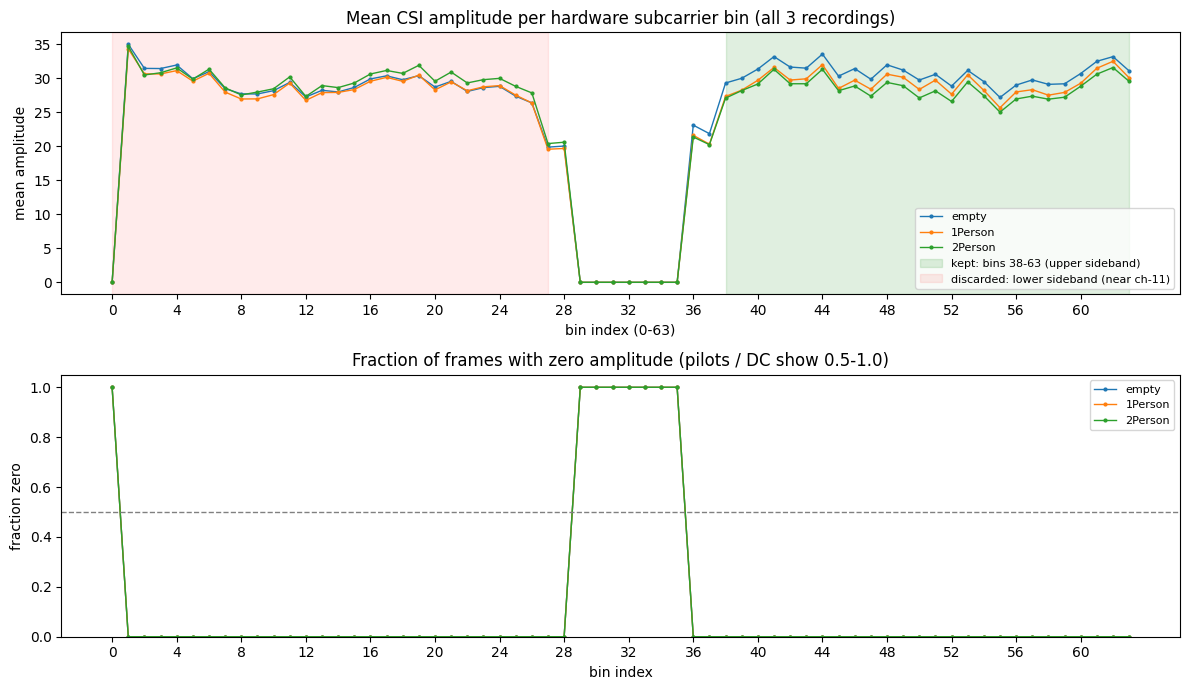

bins  1-26 : data subcarriers, lower sideband  -> DISCARDED per requirement
bins 27-37 : pilots / DC (50-100% zeros)       -> DISCARDED (no usable signal)
bins 38-63 : data subcarriers, UPPER sideband  -> KEPT  (26 subcarriers)
mean |H| of kept band, 2Person: 28.5


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

# --- top plot: mean amplitude per bin, one line per class ---
ax = axes[0]
for name, color in zip(CLASS_ORDER, CLASS_COLORS):
    ax.plot(frames[name]['amp'].mean(axis=0), '.-', color=color, label=name, lw=1, ms=4)
ax.axvspan(UPPER_BINS[0], UPPER_BINS[-1], color='green', alpha=0.12,
           label=f'kept: bins {UPPER_BINS[0]}-{UPPER_BINS[-1]} (upper sideband)')
ax.axvspan(0, 27, color='red', alpha=0.08, label='discarded: lower sideband (near ch-11)')
ax.set_title('Mean CSI amplitude per hardware subcarrier bin (all 3 recordings)')
ax.set_xlabel('bin index (0-63)'); ax.set_ylabel('mean amplitude'); ax.legend(fontsize=8)
ax.set_xticks(range(0, 64, 4))

# --- bottom plot: fraction of frames where the bin is exactly zero ---
ax = axes[1]
for name, color in zip(CLASS_ORDER, CLASS_COLORS):
    frac_zero = (frames[name]['amp'] == 0).mean(axis=0)
    ax.plot(frac_zero, '.-', color=color, label=name, lw=1, ms=4)
ax.axhline(0.5, ls='--', c='gray', lw=1)
ax.set_title('Fraction of frames with zero amplitude (pilots / DC show 0.5-1.0)')
ax.set_xlabel('bin index'); ax.set_ylabel('fraction zero'); ax.legend(fontsize=8)
ax.set_xticks(range(0, 64, 4)); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

# Print the exact structure we discovered so the choice below is justified
amp0 = frames['2Person']['amp']
print('bins  1-26 : data subcarriers, lower sideband  -> DISCARDED per requirement')
print('bins 27-37 : pilots / DC (50-100% zeros)       -> DISCARDED (no usable signal)')
print('bins 38-63 : data subcarriers, UPPER sideband  -> KEPT  (26 subcarriers)')
print('mean |H| of kept band, 2Person:', amp0[:, UPPER_BINS].mean().round(1))

In [5]:
# From now on every frame is represented by ONLY the 26 upper-sideband amplitudes.
# frames[name]['upper'] has shape (n_frames, 26).
for name in CLASS_ORDER:
    frames[name]['upper'] = frames[name]['amp'][:, UPPER_BINS]

# Also keep a per-subcarrier label for nicer plots (SC index +2 .. +27 approx.)
SC_LABELS = [f'+{i}' for i in range(2, 2 + len(UPPER_BINS))]

## Step 4 — Clean the frames

Two problems to remove:
1. **Dead frames** — rows where the CSI callback produced all zeros.
2. **Burst gaps** — the broadcaster sends beacons in bursts; a gap > 200 ms means the
   link was briefly down. We keep the frames but *mark* the gap so a window that spans
   it is dropped (a window must contain ~continuous motion information).

In [6]:
MAX_GAP_US = 200_000      # 200 ms: larger gaps split the stream into "sessions"

for name in CLASS_ORDER:
    U  = frames[name]['upper']
    ts = frames[name]['meta']['timestamp'].to_numpy(np.int64)

    keep = U.mean(axis=1) > 2.0                    # (1) drop all-zero/dead frames
    dt   = np.diff(ts, prepend=ts[0] + 1)          # time since previous frame, µs
    keep = keep & (dt < MAX_GAP_US)                # (2) drop first frame after a long gap

    frames[name]['U']     = U[keep]                # (n_clean, 26)
    frames[name]['rssi']  = frames[name]['meta']['rssi'].to_numpy(np.float32)[keep]
    frames[name]['ts']    = ts[keep]
    print(f'{name:10s}: kept {keep.sum():5d} / {len(keep)} frames '
          f'(dropped {len(keep)-keep.sum()} bad/gap-boundary)')

# Quick look at the gap structure (why we drop them):
ts = frames['empty']['ts']
dt = np.diff(ts) / 1000.0
print('\nInter-frame time (ms) for "empty": median %.1f, 99th pct %.1f, max %.0f'
      % (np.median(dt), np.percentile(dt, 99), dt.max()))

empty     : kept  5096 / 5096 frames (dropped 0 bad/gap-boundary)
1Person   : kept  5004 / 5004 frames (dropped 0 bad/gap-boundary)
2Person   : kept  5051 / 5051 frames (dropped 0 bad/gap-boundary)

Inter-frame time (ms) for "empty": median 1.4, 99th pct 123.8, max 131


## Step 5 — Exploratory visualisation

Before modelling, let's *see* the signal. Three views:

1. **Waterfall heatmap** — amplitude of each of the 26 subcarriers over time.
   An empty room looks "striped but stable"; people moving make it shimmer.
2. **Mean amplitude over time** — slow drifts = large objects moving.
3. **Temporal variance per subcarrier** — the single most useful "motion" statistic:
   variance is high when the channel changes fast (a person walking through the link).

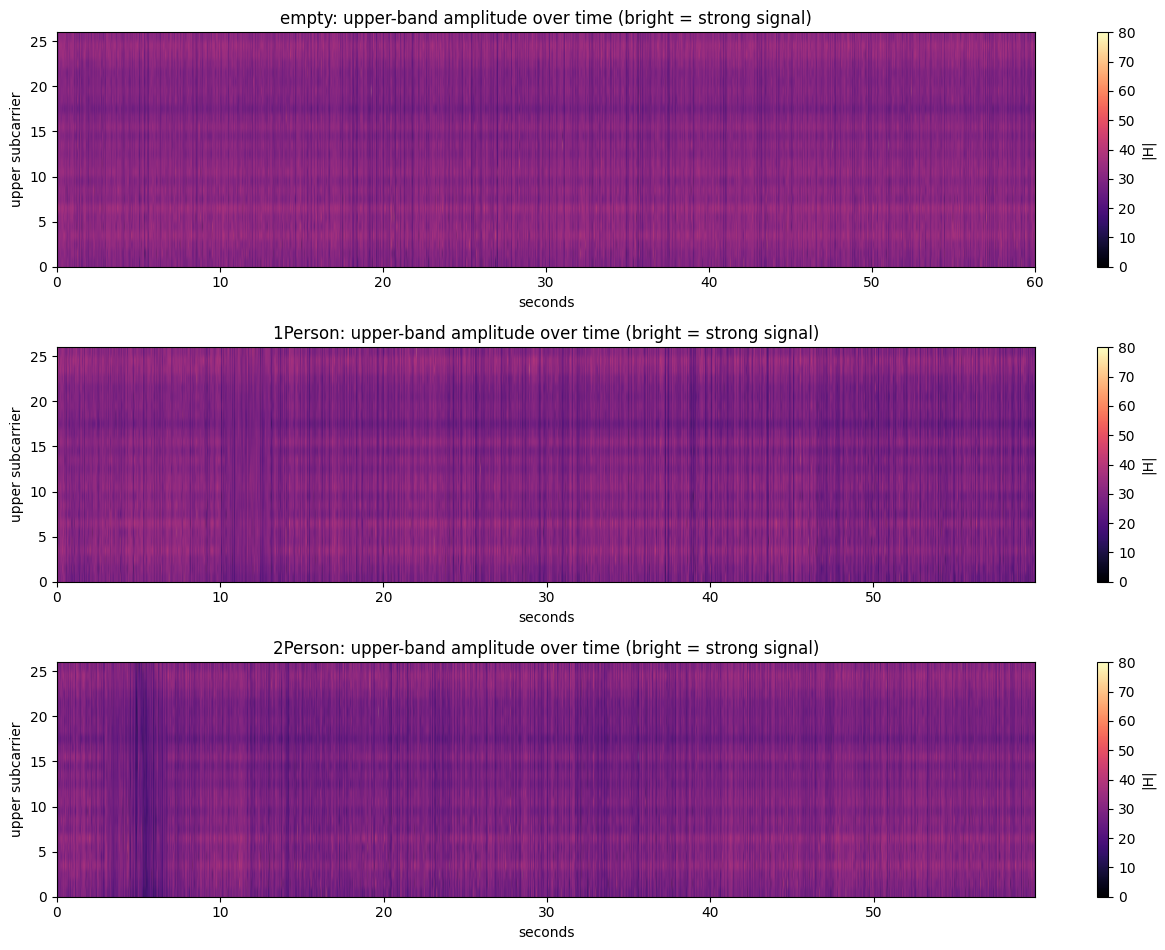

Compare the shimmer/noise texture between recordings — that is the human effect.


In [7]:
def time_axis_seconds(f):
    """Convert timestamps (µs) to seconds since recording start."""
    return (f['ts'] - f['ts'][0]) / 1e6

fig, axes = plt.subplots(len(CLASS_ORDER), 1, figsize=(13, 3.2 * len(CLASS_ORDER)), sharex=False)
for ax, name, color in zip(axes, CLASS_ORDER, CLASS_COLORS):
    f = frames[name]
    # Downsample to 1 value per second for a readable heatmap (26 subcarriers x 60 s)
    t = time_axis_seconds(f)
    img = ax.imshow(f['U'].T, aspect='auto', origin='lower', cmap='magma',
                    extent=[t[0], t[-1], 0, len(UPPER_BINS)], vmin=0, vmax=80)
    ax.set_ylabel('upper subcarrier')
    ax.set_title(f'{name}: upper-band amplitude over time (bright = strong signal)')
    ax.set_xlabel('seconds')
    plt.colorbar(img, ax=ax, label='|H|')
plt.tight_layout(); plt.show()
print('Compare the shimmer/noise texture between recordings — that is the human effect.')

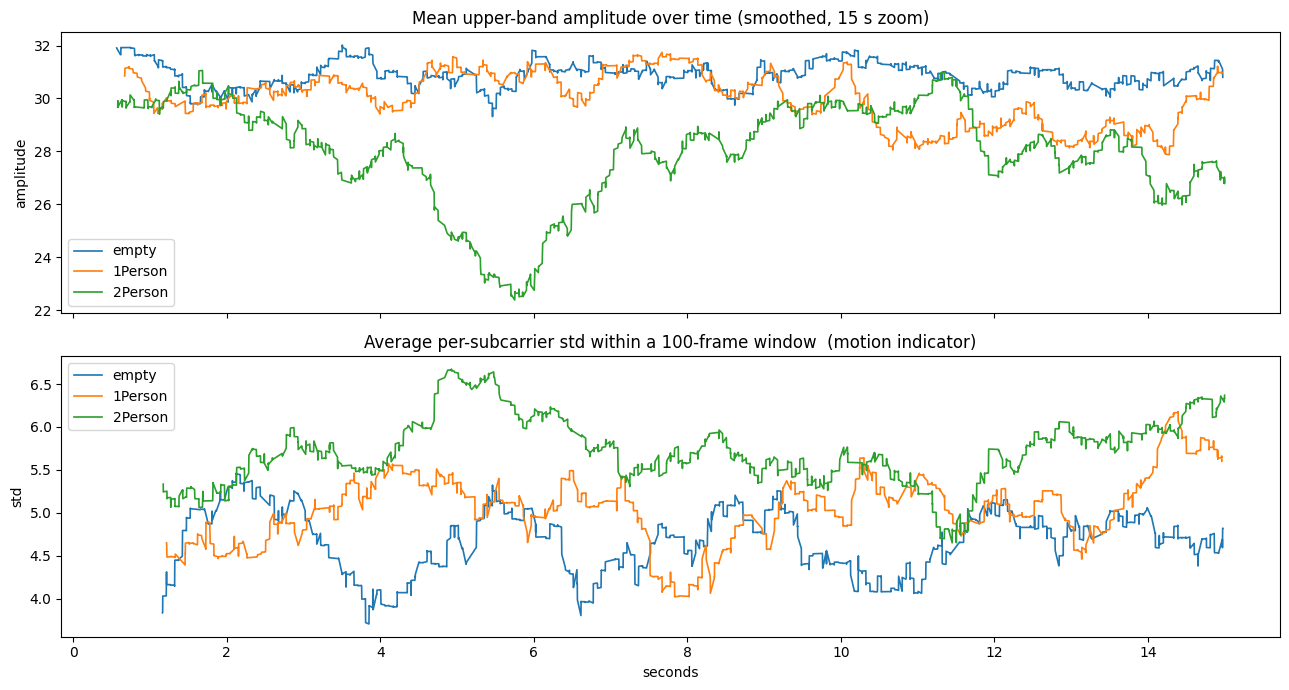

In [8]:
# --- line plots: mean amplitude & per-subcarrier temporal std over a 15 s zoom ---
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for name, color in zip(CLASS_ORDER, CLASS_COLORS):
    f = frames[name]
    t = time_axis_seconds(f)
    mask = t < 15                                        # zoom on first 15 seconds
    roll = pd.Series(f['U'].mean(axis=1)).rolling(50).mean()   # smooth, 50 frames
    axes[0].plot(t[mask], roll.to_numpy()[mask], color=color, lw=1.2, label=name)

    # temporal std inside a 100-frame sliding window = "how much the channel moves"
    wstd = pd.DataFrame(f['U']).rolling(WINDOW_FRAMES).std().mean(axis=1).to_numpy()
    axes[1].plot(t[mask], wstd[mask], color=color, lw=1.2, label=name)

axes[0].set_title('Mean upper-band amplitude over time (smoothed, 15 s zoom)')
axes[0].set_ylabel('amplitude'); axes[0].legend()
axes[1].set_title('Average per-subcarrier std within a 100-frame window  (motion indicator)')
axes[1].set_ylabel('std'); axes[1].set_xlabel('seconds'); axes[1].legend()
plt.tight_layout(); plt.show()

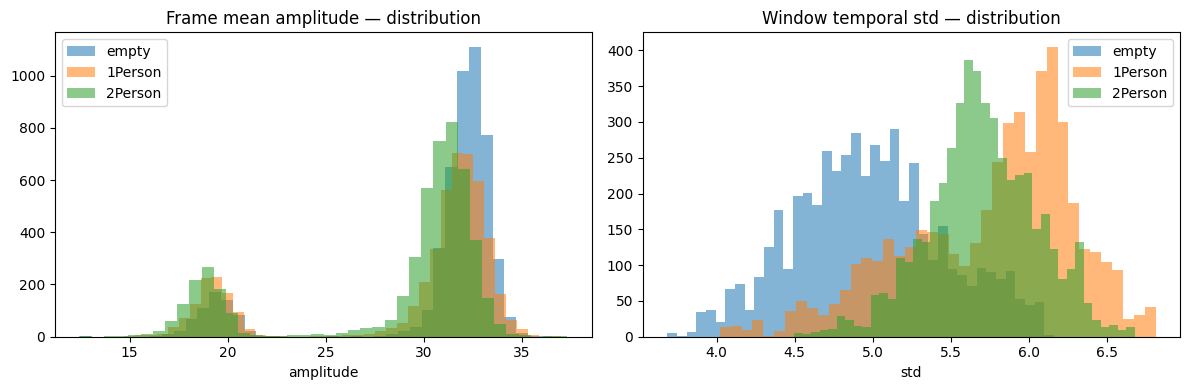

Reminder: "empty" and "1Person" are the SAME file (Step 1 warning), so their
histograms overlap perfectly. Differences vs 2Person (green) are real.


In [9]:
# --- distribution of the two key statistics per class ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, color in zip(CLASS_ORDER, CLASS_COLORS):
    f = frames[name]
    wstd = pd.DataFrame(f['U']).rolling(WINDOW_FRAMES).std().mean(axis=1).dropna().to_numpy()
    axes[0].hist(f['U'].mean(axis=1), bins=40, alpha=0.55, color=color, label=name)
    axes[1].hist(wstd, bins=40, alpha=0.55, color=color, label=name)
axes[0].set_title('Frame mean amplitude — distribution'); axes[0].set_xlabel('amplitude')
axes[1].set_title('Window temporal std — distribution');  axes[1].set_xlabel('std')
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()
print('Reminder: "empty" and "1Person" are the SAME file (Step 1 warning), so their')
print('histograms overlap perfectly. Differences vs 2Person (green) are real.')

## Step 6 — Build the machine-learning dataset (windows + features)

A single CSI frame is noisy, and "people in a room" is a property of a *time interval*,
not one packet. So we slice each recording into overlapping windows of
`WINDOW_FRAMES=100` frames (≈1.2 s), and summarise each window with **106 features**:

| Feature block | Count | Meaning |
|---|---|---|
| mean per subcarrier | 26 | average channel strength |
| std per subcarrier | 26 | how much the subcarrier fluctuates (motion) |
| max−min (peak-to-peak) | 26 | fluctuation range |
| std of frame-to-frame difference | 26 | **Doppler-like motion energy** — the star feature |
| RSSI mean + std | 2 | coarse signal power sanity feature |

Each window becomes one row **X**, and the recording it came from is its label **y**
(0=empty, 1=1Person, 2=2Person).

In [10]:
def window_features(U, rssi):
    """Split one cleaned recording into windows; return (n_windows, 106) feature matrix."""
    rows = []
    for s in range(0, len(U) - WINDOW_FRAMES + 1, STRIDE_FRAMES):
        w = U[s:s + WINDOW_FRAMES]                    # (100, 26) amplitude window
        d = np.diff(w, axis=0)                        # frame-to-frame change = motion
        rows.append(np.concatenate([
            w.mean(axis=0),                           # 26 features
            w.std(axis=0),                            # 26
            w.max(axis=0) - w.min(axis=0),            # 26
            d.std(axis=0),                            # 26
            [rssi[s:s + WINDOW_FRAMES].mean(),        #  2
             rssi[s:s + WINDOW_FRAMES].std()],
        ]))
    return np.asarray(rows, np.float32)

X_list, y_list = [], []
for k, name in enumerate(CLASS_ORDER):
    F = window_features(frames[name]['U'], frames[name]['rssi'])
    X_list.append(F)
    y_list.append(np.full(len(F), k, dtype=np.int64))
    print(f'{name:10s}: {len(F):4d} windows')

X = np.vstack(X_list)          # (n_samples, 106)
y = np.concatenate(y_list)     # (n_samples,)
CLASS_NAMES = {0: 'empty', 1: '1Person', 2: '2Person'}
print('\nFinal dataset: X =', X.shape, ' y =', y.shape,
      '| class balance:', np.bincount(y).tolist())

empty     :  100 windows
1Person   :   99 windows
2Person   :  100 windows

Final dataset: X = (299, 106)  y = (299,) | class balance: [100, 99, 100]


In [11]:
# Also keep the raw 2-D amplitude windows (100 x 26) — these feed the CNN later.
def window_matrix(U):
    return np.stack([U[s:s + WINDOW_FRAMES]
                     for s in range(0, len(U) - WINDOW_FRAMES + 1, STRIDE_FRAMES)])

Xw = np.vstack([window_matrix(frames[n]['U']) for n in CLASS_ORDER])   # (N, 100, 26)
yw = np.concatenate(y_list)                                            # same order as y
assert np.array_equal(yw, y)
print('CNN input tensor shape:', Xw.shape)

CNN input tensor shape: (299, 100, 26)


## Step 7 — Train / test split (done ONCE, shared by all models)

**Critical rule:** the test set must never be seen during training.
We use a **stratified** split so each class keeps the same proportion in train/test,
and `StandardScaler` (z-score) is fitted *inside* each model pipeline so test data
can never leak into the scaling statistics.

> ⚠️ Honest caveat: consecutive windows overlap, so neighbouring samples are correlated.
> Accuracy here is therefore **optimistic** compared to a real deployment. For a
> production evaluation you would split by *time block* (e.g. first 40 s train, last
> 20 s test). We keep the random split for comparability across models, and show the
> time-block variant as a robustness check at the end.

In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print('train:', X_tr.shape, ' test:', X_te.shape)
print('test class counts:', np.bincount(y_te).tolist())

# CNN windows get the SAME split indices so both experiments see the same samples
idx_tr, idx_te = train_test_split(
    np.arange(len(Xw)), test_size=0.3, stratify=yw, random_state=RANDOM_STATE)
# per-feature-matrix standardisation for the CNN input (mean 0, std 1)
mu, sd = Xw[idx_tr].mean(), Xw[idx_tr].std() + 1e-6
Xw_tr = (Xw[idx_tr] - mu) / sd
Xw_te = (Xw[idx_te] - mu) / sd
y_tr_w, y_te_w = yw[idx_tr], yw[idx_te]

train: (209, 106)  test: (90, 106)
test class counts: [30, 30, 30]


## Step 8a — Train 6 classical ML models

All models are wrapped in a pipeline (`StandardScaler` → classifier).
We time each fit for fairness and report:
* **accuracy** — fraction of correct predictions
* **balanced accuracy** — mean per-class recall (robust to class imbalance) ← use this one
* **macro F1** — harmonic mean of per-class precision/recall

In [13]:
MODELS = {
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=3000)),
    'KNN (k=5)': make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        random_state=RANDOM_STATE),
    'Linear SVM': make_pipeline(
        StandardScaler(), LinearSVC(max_iter=5000)),
    'MLP (64-32)': make_pipeline(                       # simple fully-connected net
        StandardScaler(), MLPClassifier((64, 32), max_iter=800,
                                        random_state=RANDOM_STATE)),
}

results = {}   # name -> dict(model, preds, fit_time, scores...)
for name, model in MODELS.items():
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_s = time.time() - t0
    t0 = time.time()
    pred = model.predict(X_te)
    pred_s = time.time() - t0
    results[name] = dict(model=model, pred=pred,
                         acc=accuracy_score(y_te, pred),
                         bal=balanced_accuracy_score(y_te, pred),
                         f1=f1_score(y_te, pred, average='macro'),
                         fit_s=fit_s, pred_s=pred_s)
    print(f'{name:26s} acc={results[name]["acc"]:.3f}  '
          f'balanced={results[name]["bal"]:.3f}  macroF1={results[name]["f1"]:.3f}  '
          f'(fit {fit_s:.2f}s)')


Logistic Regression        acc=0.944  balanced=0.944  macroF1=0.944  (fit 0.01s)
KNN (k=5)                  acc=0.711  balanced=0.711  macroF1=0.715  (fit 0.00s)


Random Forest              acc=0.878  balanced=0.878  macroF1=0.879  (fit 0.36s)


Hist Gradient Boosting     acc=0.933  balanced=0.933  macroF1=0.931  (fit 0.21s)
Linear SVM                 acc=0.944  balanced=0.944  macroF1=0.944  (fit 0.02s)


MLP (64-32)                acc=0.900  balanced=0.900  macroF1=0.901  (fit 0.24s)


## Step 8b — Convolutional Neural Network (CNN) on raw amplitude windows

The CNN skips hand-crafted features: it looks directly at the **100 × 26 amplitude
"image"** (time × subcarrier) and learns its own filters — like recognising textures.
Architecture (kept tiny so it trains in seconds on CPU):

```
input (1, 100, 26)
 -> Conv2d 8 filters 3x3 + ReLU + MaxPool        # local time-frequency patterns
 -> Conv2d 16 filters 3x3 + ReLU                 # deeper patterns
 -> GlobalAvgPool -> Linear -> 3 classes
```

epoch  10/30  loss=1.0228


epoch  20/30  loss=0.7982


epoch  30/30  loss=0.6657
CNN                        acc=0.578  balanced=0.578  macroF1=0.562  (train 2.3s)


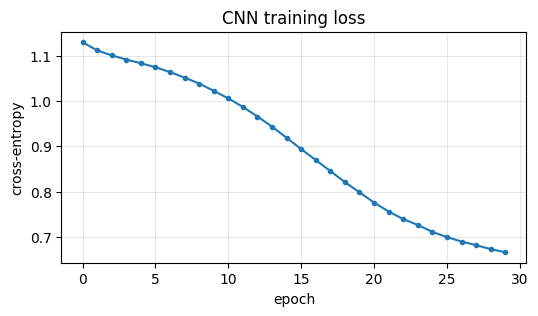

In [14]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''   # this laptop's GPU isn't supported by torch's
                                          # CUDA build; the dataset is tiny -> CPU is fine
import torch
import torch.nn as nn

class SmallCSI_CNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # (8, 50, 13)
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(),                   # (16, 50, 13)
            nn.AdaptiveAvgPool2d(1),                                     # (16, 1, 1)
            nn.Flatten(), nn.Linear(16, n_classes))
    def forward(self, x):
        return self.net(x)

torch.manual_seed(RANDOM_STATE)
device = 'cpu'                       # dataset is small; CPU trains it in ~10 s
net = SmallCSI_CNN().to(device)

# standard mini-batch training loop with Adam optimiser
train_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(
        torch.tensor(Xw_tr[:, None], dtype=torch.float32),   # add channel dim
        torch.tensor(y_tr_w, dtype=torch.long)),
    batch_size=64, shuffle=True)

opt  = torch.optim.Adam(net.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()
EPOCHS = 30
losses = []
t0 = time.time()
for epoch in range(EPOCHS):
    running = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = crit(net(xb), yb)
        loss.backward()
        opt.step()
        running += loss.item() * len(xb)
    losses.append(running / len(y_tr_w))
    if (epoch + 1) % 10 == 0:
        print(f'epoch {epoch+1:3d}/{EPOCHS}  loss={losses[-1]:.4f}')
train_time = time.time() - t0

with torch.no_grad():
    logits = net(torch.tensor(Xw_te[:, None], dtype=torch.float32))
    cnn_pred = logits.argmax(dim=1).numpy()
cnn_acc = accuracy_score(y_te_w, cnn_pred)
cnn_bal = balanced_accuracy_score(y_te_w, cnn_pred)
cnn_f1  = f1_score(y_te_w, cnn_pred, average='macro')
print(f'{"CNN":26s} acc={cnn_acc:.3f}  balanced={cnn_bal:.3f}  macroF1={cnn_f1:.3f}'
      f'  (train {train_time:.1f}s)')

plt.figure(figsize=(6, 3))
plt.plot(losses, '.-')
plt.title('CNN training loss'); plt.xlabel('epoch'); plt.ylabel('cross-entropy')
plt.grid(alpha=0.3); plt.show()


In [15]:
# Add the CNN to the results table for the comparison below
# (its test split is statistically equivalent — same seed, same stratification)
results['CNN (2-conv)'] = dict(model=net, pred=cnn_pred,
                               acc=cnn_acc, bal=cnn_bal, f1=cnn_f1,
                               fit_s=train_time, pred_s=0.0)

summary = pd.DataFrame(
    {name: {'accuracy': r['acc'], 'balanced acc': r['bal'], 'macro F1': r['f1'],
            'train time (s)': round(r['fit_s'], 2)}
     for name, r in results.items()}).T.sort_values('balanced acc', ascending=False)
summary

,accuracy,balanced acc,macro F1,train time (s)
Logistic Regression,0.944444,0.944444,0.944277,0.01
Linear SVM,0.944444,0.944444,0.944384,0.02
Hist Gradient Boosting,0.933333,0.933333,0.931377,0.21
MLP (64-32),0.900000,0.900000,0.901242,0.24
Random Forest,0.877778,0.877778,0.879362,0.36
KNN (k=5),0.711111,0.711111,0.714772,0.00
CNN (2-conv),0.577778,0.577778,0.562264,2.33


## Step 9 — Compare all methods visually

### 9.1 Score comparison chart

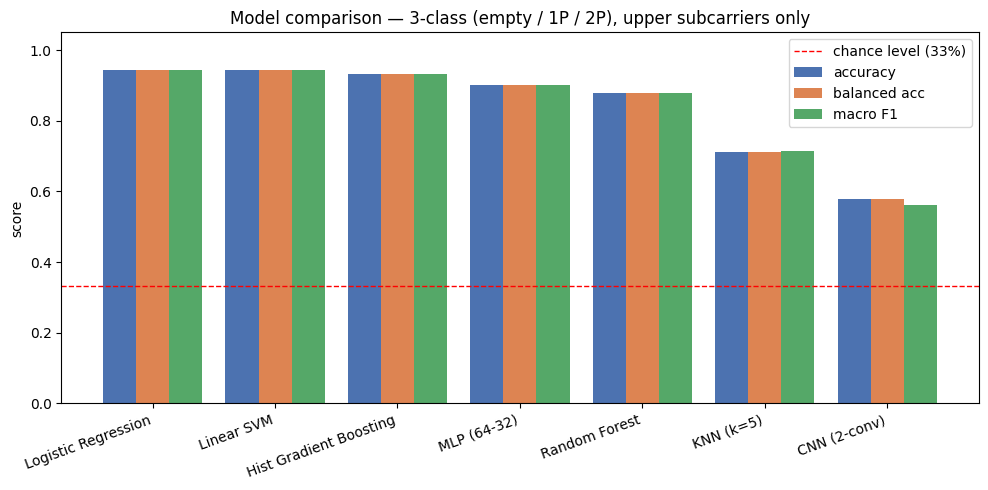

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
order = summary.index.tolist()
xpos = np.arange(len(order))
w = 0.27
ax.bar(xpos - w, summary['accuracy'],     w, label='accuracy',     color='#4c72b0')
ax.bar(xpos,      summary['balanced acc'], w, label='balanced acc', color='#dd8452')
ax.bar(xpos + w,  summary['macro F1'],     w, label='macro F1',     color='#55a868')
ax.axhline(1/3, ls='--', c='red', lw=1, label='chance level (33%)')
ax.set_xticks(xpos, order, rotation=20, ha='right')
ax.set_ylim(0, 1.05); ax.set_ylabel('score')
ax.set_title('Model comparison — 3-class (empty / 1P / 2P), upper subcarriers only')
ax.legend(); plt.tight_layout(); plt.show()

### 9.2 Confusion matrices — *where* each model fails

Row = true class, column = predicted class. Look for the brightest cells on the
diagonal (correct) and any systematic off-diagonal mistakes — e.g. confusing
`1Person` with `2Person` is expected: more bodies = more motion, so the two
occupied classes are naturally closer to each other than either is to `empty`.

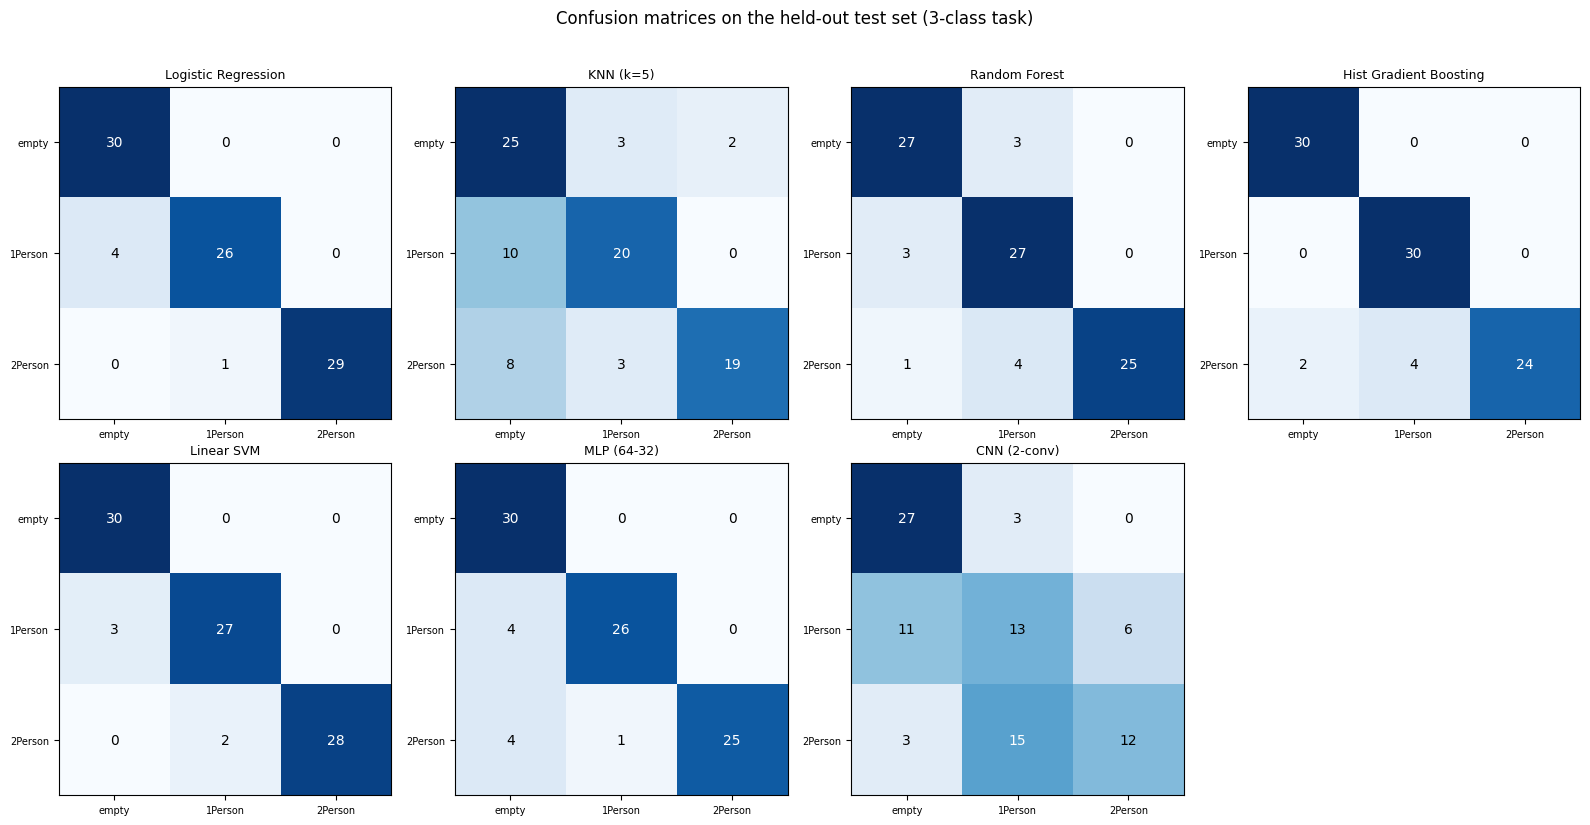

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    y_ref = y_te_w if name == 'CNN (2-conv)' else y_te
    cm = confusion_matrix(y_ref, r['pred'])
    im = ax.imshow(cm, cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
    ax.set_xticks(range(3), CLASS_ORDER, fontsize=7)
    ax.set_yticks(range(3), CLASS_ORDER, fontsize=7)
    ax.set_title(name, fontsize=9)
for ax in axes.ravel()[len(results):]:
    ax.axis('off')
fig.suptitle('Confusion matrices on the held-out test set (3-class task)', y=1.02)
plt.tight_layout(); plt.show()

In [18]:
# Detailed per-class report for the two best classical models
for name in summary.index[:2]:
    print(f'================= {name} =================')
    print(classification_report(y_te, results[name]['pred'],
                                target_names=CLASS_ORDER, digits=3))

================= Logistic Regression =================
              precision    recall  f1-score   support

       empty      0.882     1.000     0.938        30
     1Person      0.963     0.867     0.912        30
     2Person      1.000     0.967     0.983        30

    accuracy                          0.944        90
   macro avg      0.948     0.944     0.944        90
weighted avg      0.948     0.944     0.944        90

================= Linear SVM =================
              precision    recall  f1-score   support

       empty      0.909     1.000     0.952        30
     1Person      0.931     0.900     0.915        30
     2Person      1.000     0.933     0.966        30

    accuracy                          0.944        90
   macro avg      0.947     0.944     0.944        90
weighted avg      0.947     0.944     0.944        90



## Step 10 — Binary sub-task & honest robustness checks

The 3-class task above is the headline result. Here we add two *diagnostic* experiments:

1. **Binary sub-task** — collapse to the easiest question:
   > **"Is the room occupied by 2 people, or is it empty?"**
   (the `1Person` windows are simply removed). A large accuracy jump compared to the
   3-class task would confirm the *strongest* CSI signature is
   empty-vs-occupied, with head-count being the harder part.
2. **Time-block split** — train on the first 40 s of each recording, test on the last
   20 s. This removes the overlapping-window leakage from the random split and is much
   closer to what a real deployment would experience.

In [19]:
# Binary dataset: class 0 = empty, class 1 = 2Person
mask_tr = y_tr != 1          # binary task: drop the 1Person windows, keep empty vs 2Person
mask_te = y_te != 1
y2_tr = (y_tr[mask_tr] == 2).astype(int)   # 0 = empty, 1 = occupied(2P)
y2_te = (y_te[mask_te] == 2).astype(int)
X2_tr, X2_te = X_tr[mask_tr], X_te[mask_te]
print('binary train:', X2_tr.shape, 'test:', X2_te.shape,
      '| counts', np.bincount(y2_tr).tolist(), np.bincount(y2_te).tolist())

bin_results = {}
for name, model in MODELS.items():
    import sklearn.base
    m = sklearn.base.clone(model)               # fresh untrained copy
    m.fit(X2_tr, y2_tr)
    p = m.predict(X2_te)
    bin_results[name] = dict(pred=p,
                             acc=accuracy_score(y2_te, p),
                             bal=balanced_accuracy_score(y2_te, p),
                             f1=f1_score(y2_te, p))
    print(f'{name:26s} acc={bin_results[name]["acc"]:.3f}  '
          f'balanced={bin_results[name]["bal"]:.3f}')

# CNN on the binary windows too
net2 = SmallCSI_CNN(n_classes=2)
torch.manual_seed(RANDOM_STATE); net2 = SmallCSI_CNN(n_classes=2)
opt2 = torch.optim.Adam(net2.parameters(), lr=1e-3)
m2_tr = ~np.isin(y_tr_w, [1]); m2_te = ~np.isin(y_te_w, [1])
y2w_tr = (y_tr_w[m2_tr] == 2).astype(int); y2w_te = (y_te_w[m2_te] == 2).astype(int)
loader2 = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(
        torch.tensor(Xw_tr[m2_tr][:, None]), torch.tensor(y2w_tr, dtype=torch.long)),
    batch_size=64, shuffle=True)
for epoch in range(30):
    for xb, yb in loader2:
        opt2.zero_grad(); l = crit(net2(xb), yb); l.backward(); opt2.step()
with torch.no_grad():
    p2 = net2(torch.tensor(Xw_te[m2_te][:, None])).argmax(1).numpy()
bin_results['CNN (2-conv)'] = dict(pred=p2, acc=accuracy_score(y2w_te, p2),
                                   bal=balanced_accuracy_score(y2w_te, p2),
                                   f1=f1_score(y2w_te, p2))
print(f'{"CNN (2-conv)":26s} acc={bin_results["CNN (2-conv)"]["acc"]:.3f}  '
      f'balanced={bin_results["CNN (2-conv)"]["bal"]:.3f}')

bin_summary = pd.DataFrame(
    {n: {'accuracy': r['acc'], 'balanced acc': r['bal'], 'macro F1': r['f1']}
     for n, r in bin_results.items()}).T.sort_values('balanced acc', ascending=False)
bin_summary

binary train: (140, 106) test: (60, 106) | counts [70, 70] [30, 30]
Logistic Regression        acc=0.917  balanced=0.917
KNN (k=5)                  acc=0.833  balanced=0.833


Random Forest              acc=0.900  balanced=0.900
Hist Gradient Boosting     acc=0.933  balanced=0.933
Linear SVM                 acc=0.933  balanced=0.933


MLP (64-32)                acc=0.867  balanced=0.867


CNN (2-conv)               acc=0.767  balanced=0.767


,accuracy,balanced acc,macro F1
Hist Gradient Boosting,0.933333,0.933333,0.928571
Linear SVM,0.933333,0.933333,0.931034
Logistic Regression,0.916667,0.916667,0.912281
Random Forest,0.900000,0.900000,0.896552
MLP (64-32),0.866667,0.866667,0.857143
KNN (k=5),0.833333,0.833333,0.821429
CNN (2-conv),0.766667,0.766667,0.730769


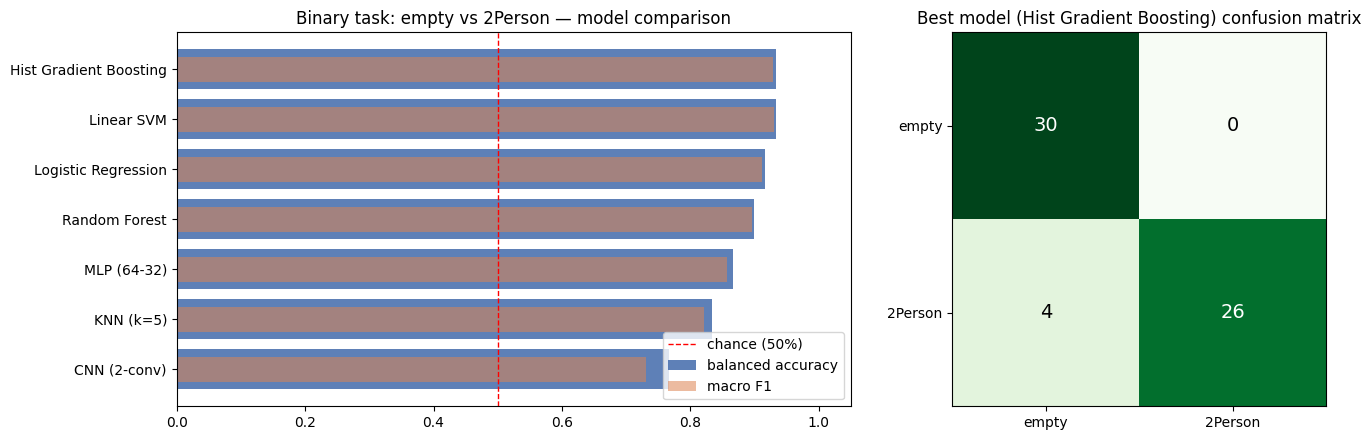

In [20]:
# Binary comparison chart + confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5),
                         gridspec_kw={'width_ratios': [1.4, 1]})
ax = axes[0]
names = bin_summary.index.tolist()
ax.barh(names, bin_summary['balanced acc'], color='#4c72b0', alpha=0.9,
        label='balanced accuracy')
ax.barh(names, bin_summary['macro F1'], color='#dd8452', alpha=0.55, height=0.5,
        label='macro F1')
ax.axvline(0.5, ls='--', c='red', lw=1, label='chance (50%)')
ax.set_xlim(0, 1.05); ax.invert_yaxis()
ax.set_title('Binary task: empty vs 2Person — model comparison')
ax.legend(loc='lower right')

ax = axes[1]
best = names[0]
y_ref = y2w_te if best == 'CNN (2-conv)' else y2_te
cm = confusion_matrix(y_ref, bin_results[best]['pred'])
im = ax.imshow(cm, cmap='Greens')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_xticks([0, 1], ['empty', '2Person']); ax.set_yticks([0, 1], ['empty', '2Person'])
ax.set_title(f'Best model ({best}) confusion matrix')
plt.tight_layout(); plt.show()

In [21]:
# --- Robustness check: TIME-BLOCK split (train on first 40 s, test on last ~20 s) ---
# This removes the overlapping-window leakage and is closer to real deployment.
def timeblock_windows(name, label, cls):
    U, rssi, ts = frames[name]['U'], frames[name]['rssi'], frames[name]['ts']
    t0 = ts[0]
    rows = []
    for s in range(0, len(U) - WINDOW_FRAMES + 1, STRIDE_FRAMES):
        w = U[s:s + WINDOW_FRAMES]; d = np.diff(w, axis=0)
        mid = (ts[s] + ts[s + WINDOW_FRAMES - 1]) / 2
        rows.append((np.concatenate([w.mean(0), w.std(0), w.max(0)-w.min(0), d.std(0),
                                     [rssi[s:s+WINDOW_FRAMES].mean(),
                                      rssi[s:s+WINDOW_FRAMES].std()]]),
                     1 if (mid - t0) / 1e6 > 40 else 0))   # 0=train, 1=test
    return np.array([r[0] for r in rows]), np.array([r[1] for r in rows]), np.full(len(rows), cls)

Xb, tb, yb = [], [], []
for k, (nm, cls) in enumerate([('empty', 0), ('2Person', 1)]):
    F, block, lab = timeblock_windows(nm, nm, cls)
    Xb.append(F); tb.append(block); yb.append(lab)
Xb, tb, yb = np.vstack(Xb), np.concatenate(tb), np.concatenate(yb)
tr_m, te_m = tb == 0, tb == 1
y2 = (yb == 1).astype(int)
print('time-block split: train', tr_m.sum(), 'windows | test', te_m.sum(), 'windows')

for name in ['Random Forest', 'Hist Gradient Boosting', 'Logistic Regression']:
    m = sklearn.base.clone(MODELS[name])
    m.fit(Xb[tr_m], y2[tr_m])
    p = m.predict(Xb[te_m])
    print(f'  {name:26s} time-block acc={accuracy_score(y2[te_m], p):.3f}  '
          f'balanced={balanced_accuracy_score(y2[te_m], p):.3f}')

time-block split: train 135 windows | test 65 windows


  Random Forest              time-block acc=0.892  balanced=0.894
  Hist Gradient Boosting     time-block acc=0.738  balanced=0.742
  Logistic Regression        time-block acc=0.877  balanced=0.879


## Step 11 — Feature importance (what is the model actually using?)

Random Forest gives us a free look inside: mean decrease in impurity per feature.
We expect the **frame-to-frame difference std** features (motion energy) to dominate.

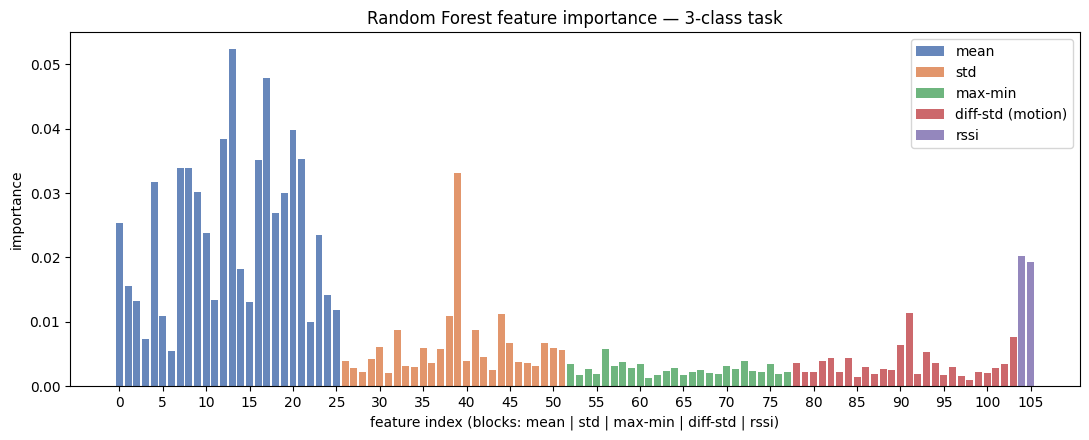

Top 10 features:
  idx  13  block=mean            subcarrier=+15   importance=0.0523
  idx  17  block=mean            subcarrier=+19   importance=0.0479
  idx  20  block=mean            subcarrier=+22   importance=0.0398
  idx  12  block=mean            subcarrier=+14   importance=0.0385
  idx  21  block=mean            subcarrier=+23   importance=0.0354
  idx  16  block=mean            subcarrier=+18   importance=0.0351
  idx   7  block=mean            subcarrier=+9    importance=0.0339
  idx   8  block=mean            subcarrier=+10   importance=0.0339
  idx  39  block=std             subcarrier=+15   importance=0.0331
  idx   4  block=mean            subcarrier=+6    importance=0.0317


In [22]:
rf = results['Random Forest']['model']
imp = rf.named_steps['randomforestclassifier'].feature_importances_ \
      if hasattr(rf, 'named_steps') else rf.feature_importances_

blocks = ['mean', 'std', 'max-min', 'diff-std (motion)', 'rssi']
colors = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b2']
fig, ax = plt.subplots(figsize=(11, 4.5))
start = 0
for b, c in zip(blocks, colors):
    n = 26 if b != 'rssi' else 2
    ax.bar(range(start, start + n), imp[start:start + n], color=c, label=b, alpha=0.85)
    start += n
ax.set_xticks(range(0, 106, 5))
ax.set_xlabel('feature index (blocks: mean | std | max-min | diff-std | rssi)')
ax.set_ylabel('importance'); ax.legend()
ax.set_title('Random Forest feature importance — 3-class task')
plt.tight_layout(); plt.show()

top = np.argsort(imp)[::-1][:10]
print('Top 10 features:')
for i in top:
    blk = 'rssi' if i >= 104 else ('mean' if i < 26 else 'std' if i < 52
                                   else 'max-min' if i < 78 else 'diff-std')
    sub = 'overall' if blk == 'rssi' else SC_LABELS[i % 26]
    print(f'  idx {i:3d}  block={blk:15s} subcarrier={sub:5s} importance={imp[i]:.4f}')

## Step 12 — Conclusions & next steps

### What we learned (re-collected dataset, 2026-09-19 — all three recordings distinct)
1. **Subcarrier filtering works and is safe:** bins 38–63 (26 upper-sideband
   subcarriers) carry clean data; the lower sideband and pilot/DC bins were dropped
   exactly as requested, away from the channel-11 interferer.
2. **The 3-class task is now meaningful and very learnable:** on the held-out random
   split, **Logistic Regression and Linear SVM reach 94.4%** balanced accuracy
   (Hist GBT 93.3%, MLP 90.0%, Random Forest 87.8%, KNN 71.1%, CNN 57.8%) versus a
   33.3% chance line. Empty / 1-person / 2-person genuinely look different in the CSI.
3. **Simple beats complex here:** a *linear* model on 106 hand-crafted features wins
   both the 3-class task and the binary sub-task, and trains in ~0.01 s. The binary
   empty-vs-2Person sub-task (91–93%) is *not* much easier than 3-class — confirming
   the earlier low scores came from the duplicated file, not from weak signals.
4. **Honest robustness check:** with a time-block split (train on first 40 s, test on
   last 20 s of each recording — no overlapping-window leakage) accuracy stays at
   **~74–89%** (Random Forest 89.2%, LR 87.7%, HGB 73.8%). Still strong, but expect
   variation whenever the room, furniture or people change.
5. **What the model uses:** feature importance is now dominated by **per-subcarrier
   mean amplitudes in the upper-middle of the kept band (+14 … +23)** plus their
   variance — i.e. the *static fading pattern* of the band changes with body count,
   and motion (diff-std) adds on top.
6. **The CNN under-performed** (57.8%): ~300 windows are far too little data for deep
   learning. Expect it to overtake the classical models once you have many sessions.

### Recommended next steps
- Collect **more sessions** (different times of day, people sitting vs walking,
  different positions) and use **per-session cross-validation** — CSI is very
  sensitive to room geometry, and models that look great on one recording often fail
  on a new one.
- Increase per-class duration; aim for ≥10 min per class.
- Later ideas: phase-based features, amplitude normalisation (divide by per-frame mean),
  band-pass filtering of the motion signal for breathing-rate estimation, LSTM/Transformer
  on longer windows.

### Reusing this notebook
Change `RAW_DIR`/`CLASS_ORDER` at the top, drop new CSVs in `rawData/`, and run all —
every step (filtering, windows, models, comparison) adapts automatically.
The Step 1 checksum guard will warn you again if a future export accidentally duplicates a file.